# Test 4: statistical analysis

## 1. Introduction

`test4.ipynb` describes the experiment and its results: 12 tasks × 5 data formats × 40 runs on Claude Haiku 4.5, measuring the **output tokens** of each reply. This notebook is only about the statistics. It uses a small set of well-known tests, and for each one it says what the test asks, what it assumes, and what its result means. It uses the same data and changes none of it.

**Three ideas every section uses**

- **Null hypothesis and p-value.** Each test starts from a "nothing is going on" claim (the null hypothesis), such as "format doesn't change output tokens". The p-value is how often data at least as extreme as ours would appear if that claim were true. A small p-value (below 0.05 here) means the data would be surprising under the null, so we reject it. A large p-value doesn't prove the null; it only means the data can't rule it out.
- **Effect size and confidence interval.** A p-value says whether a difference is real, not whether it's big. Every comparison here also reports a size (usually a ratio of output tokens) and a 95% confidence interval: the range of sizes the data is compatible with.
- **What counts as a data point.** This experiment has 2,400 replies but only 12 tasks. Section 2 explains why most tests here use one number per prompt (the average of its 40 runs) rather than every reply.

**The tests**

| Question | Test | Section |
|---|---|---|
| Why does JSON have extreme output counts? | the boxplot rule, then reading the replies | 3 |
| Is the data bell-shaped enough for t-tests? | histograms and skewness | 4 |
| Do the five formats differ at all? | one-way ANOVA | 5 |
| Which pairs of formats differ, and by how much? | paired t-test with the Bonferroni correction; permutation test as a cross-check | 6 |
| Does validity depend on format? | chi-square test | 7 |
| What does format do once the task is held fixed? Do longer prompts get longer replies? What are the odds of a valid reply? | linear regression, correlation, logistic regression | 8 |
| Do the conclusions survive other reasonable choices? | the same tests on different subsets | 9 |

In [1]:
import ast
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats

SEED = 42
N_PERM = 10_000
ALPHA = 0.05
MARGIN = 1.10  # ratios within 10% of 1 are treated as practically the same (section 6)
RESULTS_CSV = Path("../data/format_results.csv")
RAW_DIR = Path("../data/raw_format")
TASKS_DIR = Path("../format_tasks")
MODEL = "claude-haiku-4-5"

# Same order, colors and markers as test4.
DATA_FORMATS = ["csv", "json", "markdown", "xml", "prose"]
DATA_COLORS = {"csv": "#008300", "json": "#1d6fb8", "markdown": "#d4762c", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "json": "v", "markdown": "^", "xml": "s", "prose": "D"}
INK, MUTED, FAINT = "#262624", "#52514e", "#b5b4ae"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": FAINT,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})
pd.set_option("display.width", 200)


def say(*lines):
    # Show text whose numbers come from the data.
    display(Markdown("\n".join(lines)))


def p_text(p):
    return "< 0.0001" if p < 1e-4 else f"{p:.4f}"


def p_eq(p):
    # For sentences: "p < 0.0001" or "p = 0.0123".
    return "p < 0.0001" if p < 1e-4 else f"p = {p:.4f}"


def show(table, p_columns=(), digits=3):
    # Display a table with p-value columns written as text, so tiny values don't print as 0.0.
    out = table.copy()
    for column in p_columns:
        out[column] = out[column].map(p_text)
    display(out.round(digits))


responses = pd.read_csv(RESULTS_CSV)
responses = responses[responses["model"] == MODEL].copy()
responses["task"] = responses["task_id"].str[4:]  # t41_side_winrate -> side_winrate
responses["data_format"] = pd.Categorical(responses["data_format"], DATA_FORMATS, ordered=True)
responses["custom_id"] = (responses["task_id"] + "__" + responses["data_format"].astype(str)
                          + "__run" + responses["run"].map("{:02d}".format))
responses["reply"] = [(RAW_DIR / f"{cid}.txt").read_text(encoding="utf-8") if (RAW_DIR / f"{cid}.txt").exists() else ""
                      for cid in responses["custom_id"]]
responses["log_tokens"] = np.log(responses["output_tokens"])
responses = responses.sort_values(["task", "data_format", "run"]).reset_index(drop=True)

TASK_NAMES = sorted(responses["task"].unique())
N_TASKS, N_FORMATS = len(TASK_NAMES), len(DATA_FORMATS)
N_RUNS = int(responses.groupby(["task", "data_format"], observed=True).size().iloc[0])
print(f"{len(responses)} replies = {N_TASKS} tasks × {N_FORMATS} formats × {N_RUNS} runs")
print("saved replies found:", int((responses["reply"] != "").sum()))

2400 replies = 12 tasks × 5 formats × 40 runs
saved replies found: 2400


## 2. What counts as a data point

The experiment has three levels:

| Level | Count | What varies at this level |
|---|---|---|
| **Run** (one reply) | 2,400 | the model's randomness (temperature 0.7): the same prompt sent again gives a different reply |
| **Prompt** (task × format) | 60 | the data format, within one task |
| **Task** | 12 | the questions, columns and data rows |

**Every task is written in all five formats**, so formats can be compared inside the same task. That's a *paired* design, and it's why section 6 uses paired t-tests: tasks differ a lot from each other, and comparing formats within a task takes that difference out of the comparison.

**Runs aren't independent evidence about formats in general.** The 40 runs of one prompt share the same task, so they repeat that task's quirks 40 times. A test that treats 2,400 replies as 2,400 separate pieces of evidence gets p-values that are far too small for a claim like "JSON gives shorter code". The claim is about tasks in general, and we have 12 of them.

So the tests work in two steps:

1. **Average the 40 runs of each prompt.** That gives 60 numbers, one per prompt, with the run-to-run noise mostly averaged away.
2. **Test on those averages**, where each task counts once per format.

Section 6 also runs a permutation test on all 2,400 replies. That answers a narrower question: do the formats differ *on these 12 tasks*?

**The outcome is analyzed on a log scale.** `log_tokens` is the natural log of output tokens. A difference in logs is a ratio in tokens: if format A's average log is 0.2 above format B's, A uses about e^0.2 = 1.22 times the tokens. Ratios fit this data because tasks have different sizes (a format that adds 20% adds more tokens on a long task than a short one), and logs pull in the long right tail that sections 3 and 4 show.

The table below is step 1: the typical output tokens of each prompt (the average of the logs, converted back to tokens). Most tests in this notebook use these 60 numbers.

In [2]:
prompt_means = responses.groupby(["task", "data_format"], observed=True).agg(
    log_tokens=("log_tokens", "mean"), output_tokens=("output_tokens", "mean"),
    input_tokens=("input_tokens", "first"), valid_rate=("passed_all", "mean")).reset_index()
task_log = prompt_means.pivot(index="task", columns="data_format", values="log_tokens")[DATA_FORMATS]
np.exp(task_log).round(0)

data_format,csv,json,markdown,xml,prose
task,,,,,
bot_farm,360.0,229.0,504.0,408.0,499.0
early_kills,444.0,326.0,530.0,434.0,515.0
first_tower,461.0,479.0,646.0,465.0,654.0
gold_lead,459.0,319.0,513.0,478.0,516.0
inhibitors,429.0,245.0,540.0,392.0,526.0
jungle_early,477.0,316.0,605.0,441.0,607.0
jungle_picks,545.0,399.0,547.0,511.0,522.0
mid_kda,448.0,324.0,541.0,515.0,555.0
objectives,467.0,292.0,577.0,415.0,652.0


## 3. Why JSON has extreme output counts

The plot in `test4` section 7 shows a cluster of JSON replies far above the rest. This section finds what they are before any test is run, because outliers decide which tests can be trusted.

**The boxplot rule (Tukey's fence).** A value is flagged when it lies more than 1.5 × IQR above the third quartile or below the first, where IQR (interquartile range) is the width of the middle half of the data. It's the rule a boxplot uses to draw points beyond its whiskers. It's a screening rule, not a test: it marks values to look at. It doesn't say they're wrong.

In [3]:
def fences(values):
    q1, q3 = np.percentile(values, [25, 75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


# "Echo" = the reply contains the prompt's own data. This is the grader's hard-coding rule
# (format_tasks/*/test_solution.py): more than 2 of the prompt's team or player names appear.
def normalize(text):
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()


def prompt_names(task_id):
    source = (TASKS_DIR / task_id / "test_solution.py").read_text(encoding="utf-8")
    return [normalize(n) for n in ast.literal_eval(re.search(r"PROMPT_NAMES = (\[.*?\])", source, re.DOTALL).group(1))]


NAMES = {task_id: prompt_names(task_id) for task_id in responses["task_id"].unique()}
responses["names_copied"] = [sum(n in normalize(reply) for n in NAMES[task_id])
                             for task_id, reply in zip(responses["task_id"], responses["reply"])]
responses["echo"] = responses["names_copied"] > 2

rows = []
for d in DATA_FORMATS:
    sub = responses[responses["data_format"] == d]
    low, high = fences(sub["output_tokens"])
    above = sub[sub["output_tokens"] > high]
    rows.append({
        "format": d, "median": sub["output_tokens"].median(), "IQR": np.subtract(*np.percentile(sub["output_tokens"], [75, 25])),
        "upper fence": high, "max": sub["output_tokens"].max(),
        "replies above fence": len(above), "of those, echo": int(above["echo"].sum()),
        "echo replies (all)": int(sub["echo"].sum()),
        "largest non-echo reply": sub.loc[~sub["echo"], "output_tokens"].max(),
        "typical SD within one prompt": sub.groupby("task")["output_tokens"].std().median(),
    })
outlier_table = pd.DataFrame(rows).set_index("format")
outlier_table.round(0)

,median,IQR,upper fence,max,replies above fence,"of those, echo",echo replies (all),largest non-echo reply,typical SD within one prompt
format,,,,,,,,,
csv,459.0,66.0,579.0,1235,13,10,10,657,41.0
json,304.0,90.0,477.0,1788,9,9,9,434,20.0
markdown,564.0,79.0,724.0,885,7,0,0,885,49.0
xml,445.0,72.0,593.0,2198,23,1,1,694,46.0
prose,544.0,100.0,758.0,1346,8,0,0,1346,53.0


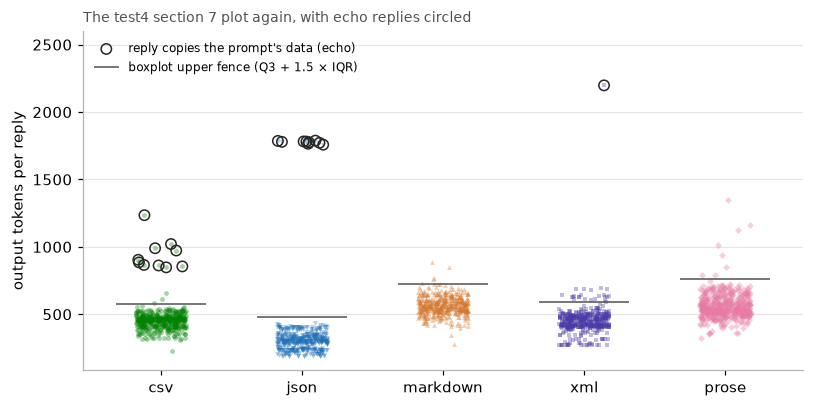

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
jitter = np.random.default_rng(SEED)
for i, d in enumerate(DATA_FORMATS):
    sub = responses[responses["data_format"] == d]
    x = i + jitter.uniform(-0.18, 0.18, len(sub))
    ax.scatter(x, sub["output_tokens"], s=10, alpha=0.35, color=DATA_COLORS[d], marker=DATA_MARKERS[d], linewidth=0)
    echo = sub["echo"].to_numpy()
    ax.scatter(x[echo], sub.loc[echo, "output_tokens"], s=46, facecolor="none", edgecolor=INK, linewidth=1,
               label="reply copies the prompt's data (echo)" if i == 0 else None)
    ax.hlines(outlier_table.loc[d, "upper fence"], i - 0.32, i + 0.32, color=MUTED, linewidth=1,
              label="boxplot upper fence (Q3 + 1.5 × IQR)" if i == 0 else None)
ax.set_xticks(range(N_FORMATS), DATA_FORMATS)
ax.set_ylabel("output tokens per reply")
ax.grid(axis="x", visible=False)
ax.set_ylim(top=2600)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("The test4 section 7 plot again, with echo replies circled", loc="left", fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

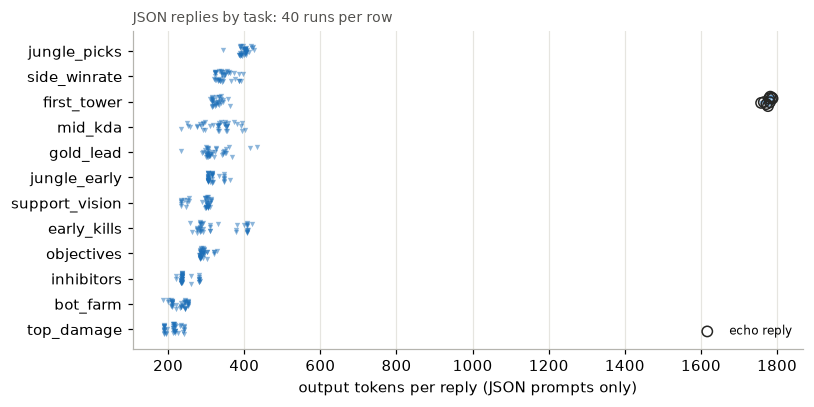

In [5]:
json_rows = responses[responses["data_format"] == "json"]
order = json_rows.groupby("task")["output_tokens"].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
jitter = np.random.default_rng(SEED)
for i, task in enumerate(order):
    sub = json_rows[json_rows["task"] == task]
    y = i + jitter.uniform(-0.22, 0.22, len(sub))
    ax.scatter(sub["output_tokens"], y, s=12, alpha=0.5, color=DATA_COLORS["json"], marker=DATA_MARKERS["json"], linewidth=0)
    echo = sub["echo"].to_numpy()
    ax.scatter(sub.loc[echo, "output_tokens"], y[echo], s=46, facecolor="none", edgecolor=INK, linewidth=1,
               label="echo reply" if echo.any() and "echo reply" not in ax.get_legend_handles_labels()[1] else None)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("output tokens per reply (JSON prompts only)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(f"JSON replies by task: {N_RUNS} runs per row", loc="left", fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

**What an echo reply looks like.** Below is the end of the JSON echo reply closest to the median length (the functions above it are the usual short ones). After answering, the model adds a test block and pastes the prompt's 20 rows into it.

In [6]:
echo_json = json_rows[json_rows["echo"]]
if echo_json.empty:
    print("no JSON echo replies found (are the saved replies in data/raw_format/?)")
else:
    row = echo_json.iloc[(echo_json["output_tokens"] - echo_json["output_tokens"].median()).abs().argmin()]
    lines = row["reply"].strip().splitlines()
    start = next((i for i, line in enumerate(lines) if "__main__" in line), len(lines) - 20)
    start = max(start - 1, 0)
    shown_top, shown_bottom = 12, 6
    print(f"=== {row['custom_id']}: {row['output_tokens']} output tokens, {len(lines)} lines; showing from line {start + 1} ===")
    print("\n".join(lines[start:start + shown_top]))
    print(f"    ... {len(lines) - start - shown_top - shown_bottom} more lines of copied rows ...")
    print("\n".join(lines[-shown_bottom:]))

=== t47_first_tower__json__run23: 1779 output tokens, 207 lines; showing from line 39 ===
# Test with the provided data
if __name__ == "__main__":
    sample_data = """[
  {
    "game": "G01",
    "team": "BNK FEARX Youth",
    "result": "loss",
    "first_tower": "no",
    "void_grubs": 2,
    "heralds": 0
  },
  {
    ... 151 more lines of copied rows ...
]"""
    
    print(f"Q1 (win rate with first tower): {q1(sample_data)}")
    print(f"Q2 (avg void grubs for winners): {q2(sample_data)}")
    print(f"Q3 (teams with herald that lost): {q3(sample_data)}")
```


**What an echo costs.** For each prompt that produced echo replies: how often it happened, the typical reply without an echo, and the extra tokens an echo adds. The last column is the prompt's input token count, which is mostly the data.

In [7]:
rows = []
for (task, d), sub in responses.groupby(["task", "data_format"], observed=True):
    k = int(sub["echo"].sum())
    if k == 0:
        continue
    usual = sub.loc[~sub["echo"], "output_tokens"].median()
    rows.append({"format": d, "task": task, "echo replies": f"{k} of {len(sub)}",
                 "usual reply (median)": usual, "echo reply (mean)": sub.loc[sub["echo"], "output_tokens"].mean(),
                 "extra tokens": sub.loc[sub["echo"], "output_tokens"].mean() - usual,
                 "× usual": sub.loc[sub["echo"], "output_tokens"].mean() / usual,
                 "prompt input tokens": sub["input_tokens"].iloc[0],
                 "echo replies valid": int(sub.loc[sub["echo"], "passed_all"].sum())})
echo_table = pd.DataFrame(rows).set_index(["format", "task"])
display(echo_table.round(1))

rows = {}
for label, sub in [("all replies", responses), ("without echo replies", responses[~responses["echo"]])]:
    grouped = sub.groupby("data_format", observed=True)["output_tokens"]
    rows[label] = pd.DataFrame({"n": grouped.size(), "mean": grouped.mean(), "median": grouped.median(), "SD": grouped.std()})
echo_effect = pd.concat(rows, axis=1)
echo_effect.round(1)

echo replies  usual reply (median)  echo reply (mean)  extra tokens  × usual  prompt input tokens  echo replies valid
format task                                                                                                                                
json   first_tower         9 of 40                 326.0             1776.3        1450.3      5.4                 1576                   0
csv    jungle_picks        7 of 40                 482.0              922.1         440.1      1.9                  480                   0
       mid_kda             1 of 40                 452.0              990.0         538.0      2.2                  675                   0
       support_vision      2 of 40                 525.0              997.0         472.0      1.9                  608                   0
xml    top_damage          1 of 40                 284.0             2198.0        1914.0      7.7                 1737                   0

all replies                      without echo replies                    
                      n   mean median     SD                    n   mean median    SD
data_format                                                                          
csv                 480  460.0  459.0   88.9                  470  449.7  457.0  52.0
json                480  329.9  304.0  208.3                  471  302.3  304.0  58.3
markdown            480  566.7  564.0   68.1                  480  566.7  564.0  68.1
xml                 480  450.7  445.0  108.3                  479  447.0  445.0  73.1
prose               480  563.0  543.5   96.8                  480  563.0  543.5  96.8

In [8]:
j = outlier_table.loc["json"]
json_echo = echo_table.loc["json"] if "json" in echo_table.index.get_level_values(0) else pd.DataFrame()
all_, clean = echo_effect["all replies"].loc["json"], echo_effect["without echo replies"].loc["json"]
say(
    f"- **How many:** {j['replies above fence']:.0f} of {len(json_rows)} JSON replies are above the fence, and "
    f"{j['of those, echo']:.0f} of them are echo replies. "
    + (f"They all come from {len(json_echo)} prompt(s): " + ", ".join(f"`{t}` ({r['echo replies']} runs)" for t, r in json_echo.iterrows()) + "."
       if len(json_echo) else ""),
    f"- **How far:** the largest JSON reply without an echo is {j['largest non-echo reply']:.0f} tokens; the echo replies are "
    + (f"about {json_echo['echo reply (mean)'].mean():.0f}, {json_echo['× usual'].mean():.1f}× the usual reply." if len(json_echo) else "absent."),
    f"- **Effect on the JSON summary:** mean {all_['mean']:.0f} → {clean['mean']:.0f} without them, SD {all_['SD']:.0f} → {clean['SD']:.0f}, "
    f"median {all_['median']:.0f} → {clean['median']:.0f}.",
    f"- **Validity:** {int(responses.loc[responses['echo'], 'passed_all'].sum())} of {int(responses['echo'].sum())} echo replies "
    "(all formats) passed the validity checks.",
)

- **How many:** 9 of 480 JSON replies are above the fence, and 9 of them are echo replies. They all come from 1 prompt(s): `first_tower` (9 of 40 runs).
- **How far:** the largest JSON reply without an echo is 434 tokens; the echo replies are about 1776, 5.4× the usual reply.
- **Effect on the JSON summary:** mean 330 → 302 without them, SD 208 → 58, median 304 → 304.
- **Validity:** 0 of 20 echo replies (all formats) passed the validity checks.

**Answer.** The JSON outliers aren't noise around the usual reply. They're a second kind of reply:

1. **One behavior.** After the three functions, the model adds a test block (in the JSON replies, under `if __name__ == "__main__":`) and pastes the prompt's full 20-row sample into it. The functions themselves are the same short ones as in the other runs.
2. **JSON makes the copy expensive.** JSON is the most token-heavy way to write the rows (`test4` section 6: about 2.5× CSV as input). Copying the data back costs about as many output tokens as the data cost as input, so a JSON echo adds far more than a CSV echo (the "extra tokens" and "prompt input tokens" columns above).
3. **JSON's normal replies are the shortest and most consistent**, because `json.loads` does all the parsing (the "typical SD within one prompt" column is smallest for JSON). The echo replies land far above everything else. A CSV echo is about 2× a usual CSV reply; a JSON echo is more than 5×.
4. **They cluster in one prompt and at one height.** The copied text is the same every time, so the echo replies are nearly the same length. That is why the plot shows a tight clump rather than a scattered tail.

**What the data can't say** is why this one prompt triggers it. One prompt isn't enough to connect it to the format or to anything about the task. CSV shows the same behavior on other tasks, so it isn't specific to JSON.

**The other formats' flagged replies are mostly not echoes** (the "of those, echo" column). The fence is computed over all 12 tasks of a format together, so it also flags ordinary replies from a task whose code runs long.

**What it means for the statistics**

- **Keep these replies.** They're real output the user pays for, not measurement errors. Deleting them would understate JSON's cost.
- **Don't summarize JSON with a mean and SD alone.** Nine replies raise the mean by about 9% and more than triple the SD. The median doesn't move.
- **Use logs and prompt averages** (section 2), which a few extreme replies move much less, and check every result without the echo replies (section 9).
- **The validity checks already catch them:** an echo fails the "not hard-coded" check.

## 4. Is the data bell-shaped enough?

The t-test and ANOVA assume the noise is roughly **normal** (bell-shaped). They tolerate mild departures, but a long tail of extreme values can mislead them. Two simple checks:

- **A histogram** of the run-to-run noise: each reply minus the average of its own prompt's 40 runs, in units of standard deviations, with the normal curve drawn over it.
- **Skewness**, a number for lopsidedness: 0 is symmetric, and a positive value means a long right tail. Beyond about ±1 is usually called strongly skewed.

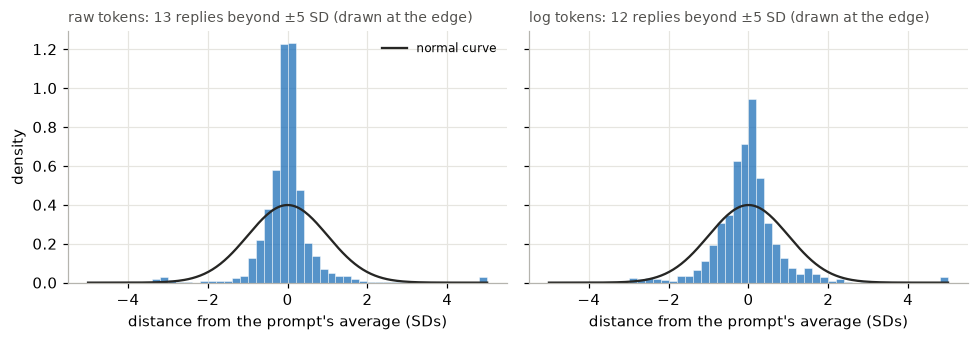

,skewness
"single replies, raw tokens (2,400)",6.91
"single replies, log tokens (2,400)",3.69
"prompt averages, log tokens (60)",0.27


In [9]:
def noise(column):
    # Each reply minus the average of its own prompt's runs.
    return responses[column] - responses.groupby(["task", "data_format"], observed=True)[column].transform("mean")


fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
grid = np.linspace(-5, 5, 200)
for ax, (title, column) in zip(axes, [("raw tokens", "output_tokens"), ("log tokens", "log_tokens")]):
    z = noise(column)
    z = z / z.std()
    ax.hist(z.clip(-5, 5), bins=np.linspace(-5, 5, 51), density=True, color=DATA_COLORS["json"], alpha=0.75,
            edgecolor="white", linewidth=0.4)
    ax.plot(grid, stats.norm.pdf(grid), color=INK, linewidth=1.5, label="normal curve")
    ax.set_title(f"{title}: {int((z.abs() > 5).sum())} replies beyond ±5 SD (drawn at the edge)", loc="left", fontsize=9, color=MUTED)
    ax.set_xlabel("distance from the prompt's average (SDs)")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

# The 60 prompt averages, with each task's level and each format's level removed: what's left is their noise.
centered = task_log.sub(task_log.mean(axis=1), axis=0)
centered = centered.sub(centered.mean(axis=0), axis=1)
skewness = pd.Series({
    "single replies, raw tokens (2,400)": stats.skew(noise("output_tokens")),
    "single replies, log tokens (2,400)": stats.skew(noise("log_tokens")),
    "prompt averages, log tokens (60)": stats.skew(centered.to_numpy().ravel()),
}, name="skewness")
skewness.round(2).to_frame()

**Reading it.**

- **Single replies aren't normal.** The histogram is taller and narrower than the bell curve in the middle and has a long right tail: most replies are close to their prompt's average, and a few are much longer. Taking logs reduces the skewness but doesn't remove it.
- **Prompt averages are better behaved.** Averaging 40 runs pulls a distribution toward normal (the central limit theorem), which is why the tests in sections 5 and 6 run on the 60 prompt averages of log tokens rather than on single replies.
- **A safety net.** Section 6 repeats the comparisons with a permutation test, which assumes nothing about the shape, and section 9 repeats them without the echo replies.

## 5. Do the formats differ at all? One-way ANOVA

**One-way ANOVA** (analysis of variance) asks one question about all five formats together.

- **Null hypothesis:** all five formats have the same average output.
- **How it works:** it compares how far apart the format averages are with how much the values vary *inside* a format. The ratio is the **F statistic**. F near 1 means the format averages are no further apart than noise would put them; a large F means they're further apart than noise explains.
- **Assumes:** roughly normal values, similar spread in each group, independent data points.
- **Effect size:** **η² (eta squared)**, the share of the variation that goes with format, from 0 to 1.
- **What it doesn't say:** which formats differ. Section 6 does that.

It's run twice below to show why section 2 matters. The first row treats all 2,400 replies as independent. The second uses the 60 prompt averages, so every prompt counts once.

In [10]:
def one_way_anova(values, groups):
    samples = [values[groups == d] for d in DATA_FORMATS]
    f = stats.f_oneway(*samples)
    grand = values.mean()
    eta2 = sum(len(s) * (s.mean() - grand) ** 2 for s in samples) / ((values - grand) ** 2).sum()
    return {"F": f.statistic, "degrees of freedom": f"{N_FORMATS - 1}, {len(values) - N_FORMATS}", "p": f.pvalue, "η²": eta2}


anova_runs = one_way_anova(responses["log_tokens"], responses["data_format"])
anova_prompts = one_way_anova(prompt_means["log_tokens"], prompt_means["data_format"])
pd.DataFrame({name: {"F": f"{a['F']:.1f}", "degrees of freedom": a["degrees of freedom"], "p": p_text(a["p"]), "η²": f"{a['η²']:.2f}"}
              for name, a in [("all 2,400 replies", anova_runs), ("60 prompt averages", anova_prompts)]}).T

,F,degrees of freedom,p,η²
"all 2,400 replies",734.1,"4, 2395",< 0.0001,0.55
60 prompt averages,37.5,"4, 55",< 0.0001,0.73


**Reading it.**

- **Both versions reject the null:** the formats don't all give the same output length. Format goes with most of the variation in the prompt averages (η²).
- **The F statistics are very different.** With 2,400 replies the test has thousands of "data points", so F is huge. With 60 prompt averages it's much smaller, and that's the honest one for a claim about formats in general. The conclusion is the same here because the effect is large; with a smaller effect the two could disagree, and the first would be overconfident.
- The second version still ignores which task each prompt belongs to, so task differences sit in the noise. Section 6 removes them by pairing, and section 8.1 by adding task to a regression.

## 6. Which formats differ, and by how much? Paired t-tests

Five formats make 10 pairs. Each pair is compared **within tasks**: for a pair A / B, every task gives one number, the difference between A's and B's average log tokens in that task. That's 12 differences per pair.

**Paired t-test**

- **Null hypothesis:** the average of the 12 differences is 0, which means a ratio of 1 (the two formats use the same output tokens).
- **How it works:** it divides the average difference by its standard error, which comes from how much the 12 differences vary. If the format is higher in nearly every task by a similar amount, the differences vary little and the test is confident. If it's higher in some tasks and lower in others, they vary a lot and it isn't.
- **Assumes:** the 12 differences are roughly normal. They're differences of averages of 40 runs, which helps (section 4).
- **Ratio and 95% CI:** the average difference, converted back from logs, is the ratio A / B: 1.24 means A typically uses 24% more output tokens than B on the same task. If the confidence interval excludes 1, the pair differs.

**Bonferroni correction.** A test at the 0.05 level gives a false alarm 5% of the time when there's no real difference. Run 10 tests and the chance of at least one false alarm is much higher (up to about 40%). The Bonferroni correction multiplies every p-value by the number of tests (10), which keeps the chance of *any* false alarm across all 10 pairs below 5%. It's the simplest correction and a strict one, so a pair that passes it is solid. (`test4` uses the Holm correction, a slightly less strict version; the verdicts here are the same under both.)

**"Tasks where higher"** isn't a test, just a count: in how many of the 12 tasks is the first format higher? It shows whether an average is consistent or driven by a few tasks.

In [11]:
PAIRS = [(a, b) for i, b in enumerate(DATA_FORMATS) for a in DATA_FORMATS[i + 1:]]


def bonferroni(p):
    return (np.asarray(p, dtype=float) * len(p)).clip(max=1)


def paired_tests(task_table, log_scale=True):
    # One row per pair of formats, from a tasks × formats table (tasks missing either format are dropped).
    rows = []
    for a, b in PAIRS:
        pair = task_table[[a, b]].dropna()
        d = pair[a] - pair[b]
        t = stats.ttest_rel(pair[a], pair[b])
        ci = t.confidence_interval(0.95)
        rows.append({
            "comparison": f"{a} / {b}",
            "ratio": np.exp(d.mean()) if log_scale else pair[a].mean() / pair[b].mean(),
            "95% CI low": np.exp(ci.low) if log_scale else np.nan,
            "95% CI high": np.exp(ci.high) if log_scale else np.nan,
            "tasks where higher": f"{int((d > 0).sum())} of {len(d)}",
            "t": t.statistic,
            "p": t.pvalue,
        })
    table = pd.DataFrame(rows).set_index("comparison")
    table["p (Bonferroni)"] = bonferroni(table["p"])
    table["differ?"] = np.where(table["p (Bonferroni)"] < ALPHA, "yes", "no")
    return table


pairwise = paired_tests(task_log)
show(pairwise, p_columns=["p", "p (Bonferroni)"], digits=3)

,ratio,95% CI low,95% CI high,tasks where higher,t,p,p (Bonferroni),differ?
comparison,,,,,,,,
json / csv,0.676,0.604,0.756,1 of 12,-7.670,< 0.0001,< 0.0001,yes
markdown / csv,1.240,1.167,1.318,12 of 12,7.808,< 0.0001,< 0.0001,yes
xml / csv,0.975,0.915,1.040,5 of 12,-0.852,0.4124,1.0000,no
prose / csv,1.225,1.135,1.323,11 of 12,5.819,0.0001,0.0012,yes
markdown / json,1.835,1.616,2.083,12 of 12,10.515,< 0.0001,< 0.0001,yes
xml / json,1.443,1.305,1.595,11 of 12,8.032,< 0.0001,< 0.0001,yes
prose / json,1.812,1.586,2.071,12 of 12,9.804,< 0.0001,< 0.0001,yes
xml / markdown,0.786,0.720,0.858,0 of 12,-6.036,< 0.0001,0.0008,yes
prose / markdown,0.988,0.950,1.027,6 of 12,-0.683,0.5086,1.0000,no


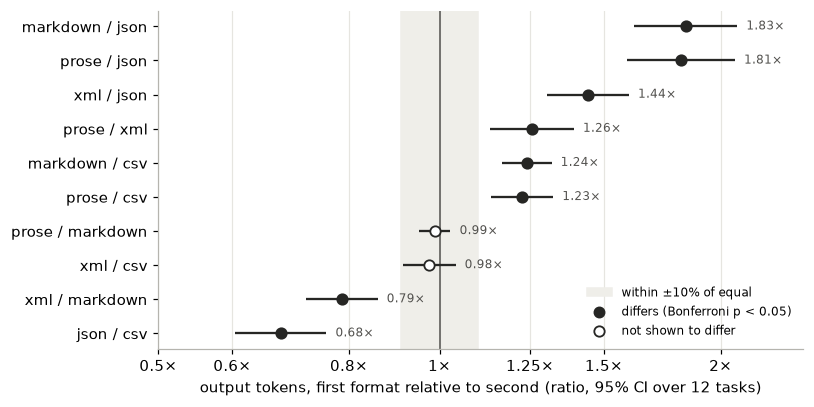

In [12]:
plot_rows = pairwise.sort_values("ratio")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.axvspan(1 / MARGIN, MARGIN, color="#efeee9", zorder=0, label=f"within ±{MARGIN - 1:.0%} of equal")
ax.axvline(1, color=MUTED, linewidth=1, zorder=1)
for i, (name, r) in enumerate(plot_rows.iterrows()):
    ax.hlines(i, r["95% CI low"], r["95% CI high"], color=INK, linewidth=1.5, zorder=2)
    ax.scatter(r["ratio"], i, s=46, zorder=3, edgecolor=INK, linewidth=1.2, facecolor=INK if r["differ?"] == "yes" else "white")
    ax.annotate(f"{r['ratio']:.2f}×", (r["95% CI high"], i), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=MUTED)
ax.scatter([], [], s=46, edgecolor=INK, facecolor=INK, label="differs (Bonferroni p < 0.05)")
ax.scatter([], [], s=46, edgecolor=INK, facecolor="white", linewidth=1.2, label="not shown to differ")
ax.set_xscale("log")
ticks = [0.5, 0.6, 0.8, 1, 1.25, 1.5, 2]
ax.set_xticks(ticks, [f"{t:g}×" for t in ticks])
ax.minorticks_off()
ax.set_xlim(0.5, 2.45)
ax.set_yticks(range(len(plot_rows)), plot_rows.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("output tokens, first format relative to second (ratio, 95% CI over 12 tasks)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Reading the plot.** Each row is one pair: the dot is the ratio and the line is its 95% confidence interval. A line that doesn't touch 1 is a pair that differs.

**"Not shown to differ" isn't the same as "equal".** A large p-value could mean no difference, or too little data to see one. The confidence interval separates the two. The gray band marks ratios within ±10% of equal, a difference small enough to ignore for most purposes (about 45 tokens on a 450-token reply; the 10% is a judgment, not a statistic). If a pair's whole interval sits inside the band, the data rules out any difference larger than 10%, so the two formats can be called **about the same**. If the interval were wide and stuck out of the band, the honest verdict would be **unclear**.

### Cross-check: the permutation test

The **permutation test** is the test `test4` section 9 uses. It makes no assumption about the shape of the data.

- **Null hypothesis:** within every task, the format label has nothing to do with the output count.
- **How it works:** shuffle the two formats' labels among the 80 replies of each task, recompute the average gap, and repeat 10,000 times. The p-value is the share of shuffles with a gap at least as large as the real one. The smallest possible p-value with 10,000 shuffles is 0.0001.
- **What's different about it:** its data points are the 2,400 replies, not the 12 tasks. So it answers the narrower question from section 2: do these two formats differ **on these 12 tasks**?

In [13]:
def permutation_p(a, b, rows=responses):
    # Shuffle the two format labels within each task; statistic = average over tasks of the gap in mean log tokens.
    rng = np.random.default_rng(SEED)
    observed, shuffled_gap = 0.0, np.zeros(N_PERM)
    for _, g in rows[rows["data_format"].isin([a, b])].groupby("task"):
        ya = g.loc[g["data_format"] == a, "log_tokens"].to_numpy()
        yb = g.loc[g["data_format"] == b, "log_tokens"].to_numpy()
        if len(ya) == 0 or len(yb) == 0:
            continue
        observed += ya.mean() - yb.mean()
        shuffled = rng.permuted(np.tile(np.concatenate([ya, yb]), (N_PERM, 1)), axis=1)
        shuffled_gap += shuffled[:, :len(ya)].mean(axis=1) - shuffled[:, len(ya):].mean(axis=1)
    return (np.sum(np.abs(shuffled_gap) >= abs(observed) - 1e-12) + 1) / (N_PERM + 1)


inside_band = (pairwise["95% CI low"] > 1 / MARGIN) & (pairwise["95% CI high"] < MARGIN)
verdicts = pd.DataFrame(index=pairwise.index)
verdicts["ratio"] = pairwise["ratio"]
verdicts["95% CI"] = [f"{lo:.2f}–{hi:.2f}" for lo, hi in zip(pairwise["95% CI low"], pairwise["95% CI high"])]
verdicts["tasks where higher"] = pairwise["tasks where higher"]
verdicts["paired t-test p (Bonferroni)"] = pairwise["p (Bonferroni)"]
verdicts["permutation p (Bonferroni)"] = bonferroni([permutation_p(a, b) for a, b in PAIRS])
verdicts["across tasks"] = np.where(pairwise["differ?"] == "yes", "differ", np.where(inside_band, "about the same", "unclear"))
verdicts["on these 12 tasks"] = np.where(verdicts["permutation p (Bonferroni)"] < ALPHA, "differ", "not shown to differ")
show(verdicts, p_columns=["paired t-test p (Bonferroni)", "permutation p (Bonferroni)"], digits=3)

split = verdicts[(verdicts["across tasks"] != "differ") & (verdicts["on these 12 tasks"] == "differ")]
say("**Pairs that differ on these 12 tasks but not across tasks:** " + (", ".join(
    f"`{name}` (ratio {r['ratio']:.2f}, higher in {r['tasks where higher']} tasks)" for name, r in split.iterrows())
    if len(split) else "none") + ".")

,ratio,95% CI,tasks where higher,paired t-test p (Bonferroni),permutation p (Bonferroni),across tasks,on these 12 tasks
comparison,,,,,,,
json / csv,0.676,0.60–0.76,1 of 12,< 0.0001,0.0010,differ,differ
markdown / csv,1.240,1.17–1.32,12 of 12,< 0.0001,0.0010,differ,differ
xml / csv,0.975,0.91–1.04,5 of 12,1.0000,0.0370,about the same,differ
prose / csv,1.225,1.13–1.32,11 of 12,0.0012,0.0010,differ,differ
markdown / json,1.835,1.62–2.08,12 of 12,< 0.0001,0.0010,differ,differ
xml / json,1.443,1.30–1.59,11 of 12,< 0.0001,0.0010,differ,differ
prose / json,1.812,1.59–2.07,12 of 12,< 0.0001,0.0010,differ,differ
xml / markdown,0.786,0.72–0.86,0 of 12,0.0008,0.0010,differ,differ
prose / markdown,0.988,0.95–1.03,6 of 12,1.0000,1.0000,about the same,not shown to differ


**Pairs that differ on these 12 tasks but not across tasks:** `xml / csv` (ratio 0.98, higher in 5 of 12 tasks).

**Reading it.**

- **Most pairs differ by both tests.** For these, the direction is the same in all or nearly all 12 tasks and the ratio is far from 1. JSON is the shortest; Markdown and prose are the longest; CSV and XML are in between.
- **Two pairs are about the same:** their ratios are close to 1 and their whole confidence intervals sit inside the ±10% band.
- **When the two tests disagree, it isn't a contradiction.** The permutation test says the two formats give different output on these particular tasks. The paired t-test says the direction isn't consistent: the first format is longer on some tasks and shorter on others, so the average is near 1. The fair summary for such a pair is "they differ task by task, with no overall winner". `test4` reports the permutation verdict, which is correct only about these 12 tasks.

## 7. Does validity depend on format? Chi-square test

Validity (did the reply pass both checks?) is a yes/no outcome, so it needs a test for counts instead of averages.

**Chi-square test of independence**

- **Null hypothesis:** the share of valid replies is the same for every format.
- **How it works:** it builds the table of format × valid/invalid and compares each count with the count expected if format made no difference. The bigger the gaps between observed and expected, the bigger the chi-square statistic.
- **Assumes:** every expected count is at least about 5, and the replies are independent.

In [14]:
counts = pd.crosstab(responses["data_format"], responses["passed_all"]).rename(columns={False: "invalid", True: "valid"})
chi2 = stats.chi2_contingency(counts)
expected = pd.DataFrame(chi2.expected_freq, index=counts.index, columns=["expected invalid", "expected valid"])
validity = pd.concat([counts, expected], axis=1)
validity["valid rate"] = counts["valid"] / counts.sum(axis=1)
display(validity.round(3))
say(f"**Chi-square:** χ²({chi2.dof}) = {chi2.statistic:.1f}, {p_eq(chi2.pvalue)}; smallest expected count = {chi2.expected_freq.min():.0f}.")

,invalid,valid,expected invalid,expected valid,valid rate
data_format,,,,,
csv,10,470,89.0,391.0,0.979
json,9,471,89.0,391.0,0.981
markdown,295,185,89.0,391.0,0.385
xml,89,391,89.0,391.0,0.815
prose,42,438,89.0,391.0,0.912


**Chi-square:** χ²(4) = 790.2, p < 0.0001; smallest expected count = 89.

**The catch is the independence assumption** (section 2 again). The 40 runs of a prompt share one task and one format, and validity can fail for a reason specific to that prompt. If a format's failures all come from one task, the pooled counts make it look like a property of the format when it's a property of that one prompt. The chi-square test can't see this, so the per-task view below goes with it. Each gray dot is one task's valid rate for that format.

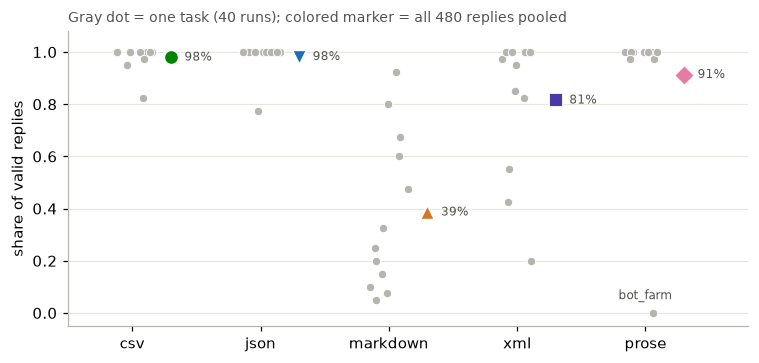

,valid rate (all replies),tasks at 95% or more,tasks below 50%,tasks where it's below CSV,share of its failures from its worst task
data_format,,,,,
csv,0.98,11,0,0,0.70
json,0.98,11,0,1,1.00
markdown,0.39,0,8,12,0.13
xml,0.81,7,2,7,0.36
prose,0.91,11,1,2,0.95


In [15]:
task_valid = prompt_means.pivot(index="task", columns="data_format", values="valid_rate")[DATA_FORMATS]
fig, ax = plt.subplots(figsize=(7, 3.4))
jitter = np.random.default_rng(SEED)
for i, d in enumerate(DATA_FORMATS):
    ax.scatter(i + jitter.uniform(-0.16, 0.16, N_TASKS), task_valid[d], s=30, color=FAINT, edgecolor="white", linewidth=0.6, zorder=2)
    ax.scatter(i + 0.3, validity.loc[d, "valid rate"], s=90, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
               edgecolor="white", linewidth=1.2)
    ax.annotate(f"{validity.loc[d, 'valid rate']:.0%}", (i + 0.3, validity.loc[d, "valid rate"]), xytext=(9, 0),
                textcoords="offset points", va="center", fontsize=8, color=MUTED)
    lowest = task_valid[d].idxmin()
    if task_valid[d].min() < 0.5 and (task_valid[d] < 0.5).sum() == 1:
        ax.annotate(lowest, (i, task_valid.loc[lowest, d]), xytext=(0, 9), textcoords="offset points", ha="center",
                    fontsize=8, color=MUTED)
ax.set_xticks(range(N_FORMATS), DATA_FORMATS)
ax.set_xlim(-0.5, N_FORMATS - 0.2)
ax.set_ylim(-0.05, 1.08)
ax.set_ylabel("share of valid replies")
ax.grid(axis="x", visible=False)
ax.set_title("Gray dot = one task (40 runs); colored marker = all 480 replies pooled", loc="left", fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

failures = 1 - task_valid
by_task = pd.DataFrame({
    "valid rate (all replies)": validity["valid rate"],
    "tasks at 95% or more": (task_valid >= 0.95).sum(),
    "tasks below 50%": (task_valid < 0.5).sum(),
    "tasks where it's below CSV": [(task_valid[d] < task_valid["csv"]).sum() for d in DATA_FORMATS],
    "share of its failures from its worst task": failures.max() / failures.sum(),
})
by_task.round(2)

**Reading it.**

- **Validity does depend on format.** The chi-square test rejects the null, and the gaps between observed and expected counts are large, not just detectable.
- **Markdown's low validity is a property of the format here:** it's below CSV in every task.
- **Prose looks worse than it is.** Nearly all of its failures come from one task where every reply fails; everywhere else it's at or near 100%. That's evidence that *this prompt* breaks, not that prose lowers validity in general.
- **XML is in between:** it's below CSV in about half the tasks, with most of its failures in a few of them. Twelve tasks aren't enough to say whether XML lowers validity in general.
- CSV and JSON have few failures at all, and those are the echo replies of section 3.

## 8. Regression

Regression describes how an outcome changes with one or more predictors, and tests whether each predictor matters. Three regressions fit this experiment, one for each kind of question.

### 8.1 Linear regression with format and task

**The model:** average log tokens of a prompt = a baseline + an amount for its format + an amount for its task, fitted to the 60 prompt averages.

- **Categories as predictors.** Format isn't a number, so it enters as **dummy variables**: one yes/no column each for JSON, Markdown, XML and prose. CSV has no column, which makes it the **baseline**. Each format's coefficient is then its difference from CSV.
- **"Holding task fixed."** Task enters the same way. With task in the model, a format's coefficient compares it with CSV *on the same task*, which is what the paired t-test does.
- **Reading a coefficient.** The outcome is in logs, so e^coefficient is a ratio: e^−0.39 = 0.68 means 0.68× CSV's output tokens. Each coefficient has a t-test whose null hypothesis is "this coefficient is 0" (the format is the same as CSV).
- **R²** is the share of the variation in the outcome that the model explains, from 0 to 1.
- **F-test for format.** Compares the model with and without the format columns: does adding format explain more than chance would? It's the ANOVA question of section 5, now with task held fixed.

In [16]:
def ols(X, y):
    # Ordinary least squares. X: DataFrame of predictors, including an "intercept" column of 1s.
    A, b = X.to_numpy(dtype=float), np.asarray(y, dtype=float)
    coef = np.linalg.lstsq(A, b, rcond=None)[0]
    resid = b - A @ coef
    df = len(b) - A.shape[1]
    se = np.sqrt(np.diag(resid @ resid / df * np.linalg.inv(A.T @ A)))
    half = stats.t.ppf(0.975, df) * se
    table = pd.DataFrame({"coefficient": coef, "std. error": se, "t": coef / se, "p": 2 * stats.t.sf(np.abs(coef / se), df),
                          "95% CI low": coef - half, "95% CI high": coef + half}, index=X.columns)
    return table, {"R²": 1 - resid @ resid / ((b - b.mean()) ** 2).sum(), "SSE": resid @ resid, "df": df}


def dummies(series, baseline):
    return pd.get_dummies(series.astype(str)).drop(columns=baseline).astype(float)


intercept = pd.Series(1.0, index=prompt_means.index, name="intercept")
format_columns = dummies(prompt_means["data_format"], "csv")[DATA_FORMATS[1:]]
task_columns = dummies(prompt_means["task"], TASK_NAMES[0])

fit_format, info_format = ols(pd.concat([intercept, format_columns], axis=1), prompt_means["log_tokens"])
fit_task, info_task = ols(pd.concat([intercept, task_columns], axis=1), prompt_means["log_tokens"])
fit_both, info_both = ols(pd.concat([intercept, format_columns, task_columns], axis=1), prompt_means["log_tokens"])

format_effects = fit_both.loc[DATA_FORMATS[1:]].copy()
format_effects.insert(0, "ratio vs CSV", np.exp(format_effects["coefficient"]))
format_effects["ratio CI low"] = np.exp(format_effects.pop("95% CI low"))
format_effects["ratio CI high"] = np.exp(format_effects.pop("95% CI high"))
show(format_effects, p_columns=["p"], digits=3)

n_format = len(DATA_FORMATS) - 1
f_format = ((info_task["SSE"] - info_both["SSE"]) / n_format) / (info_both["SSE"] / info_both["df"])
p_format = stats.f.sf(f_format, n_format, info_both["df"])
say(f"**R²:** format only {info_format['R²']:.2f}; task only {info_task['R²']:.2f}; format + task {info_both['R²']:.2f}.",
    "",
    f"**F-test for format, task held fixed:** F({n_format}, {info_both['df']}) = {f_format:.1f}, {p_eq(p_format)} "
    f"(one-way ANOVA on the same 60 averages, section 5: F = {anova_prompts['F']:.1f}).")

,ratio vs CSV,coefficient,std. error,t,p,ratio CI low,ratio CI high
json,0.676,-0.391,0.043,-9.069,< 0.0001,0.620,0.738
markdown,1.240,0.215,0.043,4.993,< 0.0001,1.137,1.353
xml,0.975,-0.025,0.043,-0.578,0.5665,0.894,1.064
prose,1.225,0.203,0.043,4.711,< 0.0001,1.123,1.337


**R²:** format only 0.73; task only 0.14; format + task 0.88.

**F-test for format, task held fixed:** F(4, 44) = 64.9, p < 0.0001 (one-way ANOVA on the same 60 averages, section 5: F = 37.5).

**Reading it.**

- **The ratios are the same as the paired t-tests' ratios against CSV** (section 6). That's expected: with every task in every format, both methods compare formats inside tasks. The regression gets all four comparisons from one model.
- **Same verdicts:** JSON, Markdown and prose differ from CSV; XML doesn't.
- **R²:** format alone explains most of the variation in the prompt averages, and adding task explains about half of what's left. The rest is how much the format effect changes from task to task.
- **Holding task fixed makes the test sharper.** The F for format is larger here than in section 5's one-way ANOVA on the same 60 numbers, because task differences are no longer counted as noise.
- **One difference from section 6:** the regression uses a single noise estimate for all formats, while each paired t-test uses its own pair's. So the confidence intervals differ a little; the paired intervals are the safer ones to quote.

### 8.2 Simple linear regression: do longer prompts get longer replies?

Formats differ a lot in **input** tokens (`test4` section 6: JSON and XML take about 2.4× CSV's). A natural question is whether a prompt that costs more to read also costs more to answer.

- **Correlation (r)** measures how closely two numbers move together on a straight line, from −1 to +1; 0 means no straight-line relationship.
- **Simple linear regression** fits the line: output tokens = intercept + slope × input tokens. The **slope** is the change in output tokens per extra input token, and its t-test has the null hypothesis "the slope is 0". **r²** is the share of variation the line explains.

Each point below is one prompt (its input tokens, and the average output tokens of its 40 runs).

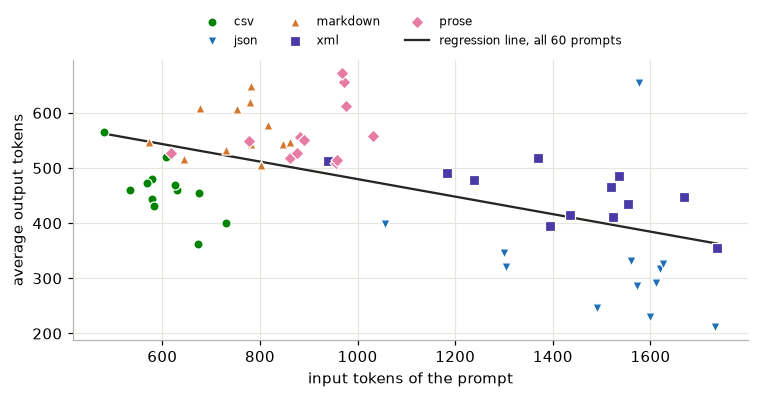

**All 60 prompts:** slope = -0.159 output tokens per input token, r = -0.57, r² = 0.32, p < 0.0001.

**Input tokens with format held fixed** (a regression with input tokens and the format dummies): slope = -0.109 (95% CI -0.231 to 0.014), p = 0.0813.

**Within each format separately:**

,prompts,slope,r
format,,,
csv,12,-0.54,-0.70
json,12,-0.14,-0.22
markdown,12,0.03,0.06
xml,12,-0.15,-0.65
prose,12,0.19,0.39


In [17]:
line = stats.linregress(prompt_means["input_tokens"], prompt_means["output_tokens"])

fig, ax = plt.subplots(figsize=(7, 3.8))
for d in DATA_FORMATS:
    sub = prompt_means[prompt_means["data_format"] == d]
    ax.scatter(sub["input_tokens"], sub["output_tokens"], s=36, color=DATA_COLORS[d], marker=DATA_MARKERS[d],
               edgecolor="white", linewidth=0.8, label=d, zorder=3)
xs = np.array([prompt_means["input_tokens"].min(), prompt_means["input_tokens"].max()])
ax.plot(xs, line.intercept + line.slope * xs, color=INK, linewidth=1.5, zorder=2, label="regression line, all 60 prompts")
ax.set_xlabel("input tokens of the prompt")
ax.set_ylabel("average output tokens")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.2))
plt.tight_layout()
plt.show()

rows = []
for d in DATA_FORMATS:
    sub = prompt_means[prompt_means["data_format"] == d]
    fit = stats.linregress(sub["input_tokens"], sub["output_tokens"])
    rows.append({"format": d, "prompts": len(sub), "slope": fit.slope, "r": fit.rvalue})
within = pd.DataFrame(rows).set_index("format")

fit_input, info_input = ols(pd.concat([intercept, prompt_means["input_tokens"].astype(float), format_columns], axis=1),
                            prompt_means["output_tokens"])
input_row = fit_input.loc["input_tokens"]

say(f"**All 60 prompts:** slope = {line.slope:.3f} output tokens per input token, r = {line.rvalue:.2f}, "
    f"r² = {line.rvalue ** 2:.2f}, {p_eq(line.pvalue)}.",
    "",
    f"**Input tokens with format held fixed** (a regression with input tokens and the format dummies): "
    f"slope = {input_row['coefficient']:.3f} (95% CI {input_row['95% CI low']:.3f} to {input_row['95% CI high']:.3f}), {p_eq(input_row['p'])}.",
    "",
    "**Within each format separately:**")
within.round(2)

**Reading it.**

- **Across all prompts the slope is negative:** prompts with more input tokens got *shorter* replies. Taken alone, that reads as "longer prompts cause shorter answers".
- **That reading is wrong, and the plot shows why.** The points form clusters by format. JSON and XML sit at the right (many input tokens); JSON's replies are the shortest, and the long replies of Markdown and prose sit at the left. The line connects the clusters. It's describing the difference between formats, not an effect of prompt length. This is **confounding**: format changes both the input count and the output count.
- **Inside a format the relationship isn't consistent:** the slopes are negative for some formats and positive for others. Once format is held fixed, the slope for input tokens is smaller and no longer significant. Its interval only just includes 0, so a small relationship within formats can't be ruled out, but there's no evidence that longer prompts get longer replies.
- **What it means for the project:** input cost and output cost are separate things. The formats that are most expensive to send (JSON, XML) aren't the ones that are most expensive to get an answer from, so both have to be measured; one can't be predicted from the other.

### 8.3 Logistic regression: the odds of a valid reply

Linear regression needs a numeric outcome. Validity is yes/no, and **logistic regression** is the standard regression for that.

- **Odds** are the chance of a valid reply divided by the chance of an invalid one: a 98% valid rate is odds of 49 to 1.
- **The model** predicts the log of the odds from the format dummies (CSV is the baseline again).
- **Odds ratio:** e^coefficient. An odds ratio of 0.10 means the odds of a valid reply are a tenth of CSV's; 1 means the same as CSV. Each has a test with the null hypothesis "the odds ratio is 1".

It's fitted to all 2,400 replies, so it has the same weakness as the chi-square test in section 7: it treats replies as independent. Task can't be added as a predictor here, because many prompts are 100% valid or 0% valid, and the model has no finite answer for those.

In [18]:
def logistic(X, y, steps=30):
    # Logistic regression fitted by Newton's method, the standard algorithm.
    A, b = X.to_numpy(dtype=float), np.asarray(y, dtype=float)
    coef = np.zeros(A.shape[1])
    for _ in range(steps):
        p = 1 / (1 + np.exp(-A @ coef))
        coef = coef + np.linalg.solve(A.T @ (A * (p * (1 - p))[:, None]), A.T @ (b - p))
    p = 1 / (1 + np.exp(-A @ coef))
    se = np.sqrt(np.diag(np.linalg.inv(A.T @ (A * (p * (1 - p))[:, None]))))
    return pd.DataFrame({"coefficient": coef, "std. error": se, "p": 2 * stats.norm.sf(np.abs(coef / se)),
                         "odds ratio vs CSV": np.exp(coef), "OR CI low": np.exp(coef - 1.96 * se),
                         "OR CI high": np.exp(coef + 1.96 * se)}, index=X.columns)


X = pd.concat([pd.Series(1.0, index=responses.index, name="intercept"),
               dummies(responses["data_format"], "csv")[DATA_FORMATS[1:]]], axis=1)
fit_valid = logistic(X, responses["passed_all"])
odds = fit_valid.loc[DATA_FORMATS[1:]].copy()
odds.insert(0, "valid rate", validity["valid rate"].reindex(odds.index))
odds.insert(1, "odds of valid", (counts["valid"] / counts["invalid"]).reindex(odds.index))
show(odds[["valid rate", "odds of valid", "odds ratio vs CSV", "OR CI low", "OR CI high", "p"]], p_columns=["p"], digits=3)
say(f"CSV (the baseline): valid rate {validity.loc['csv', 'valid rate']:.1%}, "
    f"odds of valid {counts.loc['csv', 'valid'] / counts.loc['csv', 'invalid']:.0f} to 1.")

,valid rate,odds of valid,odds ratio vs CSV,OR CI low,OR CI high,p
json,0.981,52.333,1.113,0.448,2.765,0.8168
markdown,0.385,0.627,0.013,0.007,0.026,< 0.0001
xml,0.815,4.393,0.093,0.048,0.182,< 0.0001
prose,0.912,10.429,0.222,0.110,0.448,< 0.0001


CSV (the baseline): valid rate 97.9%, odds of valid 47 to 1.

**Reading it.**

- **JSON's odds ratio is near 1** with an interval that includes 1: its validity is the same as CSV's.
- **Markdown, XML and prose have odds ratios well below 1:** lower odds of a valid reply than CSV, with Markdown by far the lowest.
- **These p-values are too confident for a general claim,** for the reason in section 7: the replies come in groups of 40 per prompt. The per-task view there shows which of these gaps hold across tasks (Markdown) and which come from a few prompts (prose).

## 9. Do the conclusions depend on our choices?

Every analysis makes choices another analyst could make differently. This section repeats the paired t-tests of section 6 under the other reasonable choices. Conclusions that hold under all of them can be stated plainly; ones that flip need a caveat.

| Version | What it changes | Why try it |
|---|---|---|
| main | all replies, log tokens (section 6) | |
| without echo | drops the replies that copy the prompt's data (section 3) | do a few extreme replies drive the result? |
| valid only | drops replies that failed a validity check | is the effect caused by broken replies? |
| raw tokens | ordinary averages of tokens instead of logs | does the log scale create or hide anything? |

**A caution about "valid only".** Validity itself depends on format (section 7), so keeping only valid replies compares different kinds of replies across formats: nearly all of JSON's, but under half of Markdown's. Read that column as a check, not as a better estimate. Tasks where a format has no valid reply at all are left out of that format's pairs.

In [19]:
def rerun(rows, column="log_tokens"):
    table = rows.pivot_table(index="task", columns="data_format", values=column, aggfunc="mean", observed=True).reindex(columns=DATA_FORMATS)
    tests = paired_tests(table, log_scale=(column == "log_tokens"))
    return tests["ratio"], tests["differ?"] == "yes"


versions = {
    "main": rerun(responses),
    "without echo": rerun(responses[~responses["echo"]]),
    "valid only": rerun(responses[responses["passed_all"]]),
    "raw tokens": rerun(responses, column="output_tokens"),
}
sensitivity = pd.DataFrame({name: ratio for name, (ratio, _) in versions.items()})
differs = pd.DataFrame({name: flag for name, (_, flag) in versions.items()}, index=sensitivity.index)
sensitivity["differs in"] = [f"{row.sum()} of {len(row)} versions" for _, row in differs.iterrows()]
sensitivity["verdict changes in"] = [", ".join(differs.columns[row != row["main"]]) or "none" for _, row in differs.iterrows()]
display(sensitivity.round(3))
stable = (sensitivity["verdict changes in"] == "none").sum()
say(f"**{stable} of {len(sensitivity)} pairs keep the same verdict in all {len(versions)} versions.**")

,main,without echo,valid only,raw tokens,differs in,verdict changes in
comparison,,,,,,
json / csv,0.676,0.664,0.664,0.717,4 of 4 versions,none
markdown / csv,1.240,1.258,1.279,1.232,4 of 4 versions,none
xml / csv,0.975,0.985,1.032,0.980,0 of 4 versions,none
prose / csv,1.225,1.242,1.231,1.224,4 of 4 versions,none
markdown / json,1.835,1.894,1.925,1.718,4 of 4 versions,none
xml / json,1.443,1.483,1.554,1.366,4 of 4 versions,none
prose / json,1.812,1.871,1.847,1.706,4 of 4 versions,none
xml / markdown,0.786,0.783,0.807,0.795,4 of 4 versions,none
prose / markdown,0.988,0.988,0.972,0.993,0 of 4 versions,none


**10 of 10 pairs keep the same verdict in all 4 versions.**

**Reading it.** The pairs whose verdict never changes are the solid findings: neither the echo replies, nor invalid replies, nor the log scale decides them. Where a ratio moves between columns, the size of the move is the uncertainty that comes from the analyst's choices, on top of the statistical uncertainty in the confidence intervals.

## 10. Summary

The numbers below are computed from the data, so they stay correct if the notebook is re-run.

In [20]:
def pair_list(names):
    return "; ".join(f"{n} = {pairwise.loc[n, 'ratio']:.2f}× (CI {pairwise.loc[n, '95% CI low']:.2f}–{pairwise.loc[n, '95% CI high']:.2f}, "
                     f"higher in {pairwise.loc[n, 'tasks where higher']} tasks)" for n in names) or "none"


unstable = sensitivity.index[sensitivity["verdict changes in"] != "none"]
say(
    f"- **Outliers (section 3):** {int(responses['echo'].sum())} of {len(responses)} replies copy the prompt's data into a test block "
    f"({', '.join(f'{d} {int(n)}' for d, n in responses.groupby('data_format', observed=True)['echo'].sum().items() if n)}). "
    f"The JSON ones are the extreme points in `test4` section 7; they raise JSON's mean by about "
    f"{echo_effect['all replies'].loc['json', 'mean'] / echo_effect['without echo replies'].loc['json', 'mean'] - 1:.0%}.",
    "- **Shape (section 4):** single replies have a long right tail, so the tests use prompt averages of log tokens.",
    f"- **Any difference (section 5):** yes. One-way ANOVA on the 60 prompt averages: F = {anova_prompts['F']:.1f}, {p_eq(anova_prompts['p'])}; "
    f"format goes with {anova_prompts['η²']:.0%} of the variation.",
    f"- **Pairs that differ (section 6, paired t-tests, Bonferroni):** {pair_list(verdicts.index[verdicts['across tasks'] == 'differ'])}.",
    f"- **Pairs that are about the same (within ±{MARGIN - 1:.0%}):** {pair_list(verdicts.index[verdicts['across tasks'] == 'about the same'])}.",
    f"- **Unclear pairs:** {pair_list(verdicts.index[verdicts['across tasks'] == 'unclear'])}.",
    "- **Permutation test vs. paired t-test (section 6):** " + (", ".join(f"`{n}`" for n in split.index) + " differ on these 12 tasks "
       "but not in a consistent direction, so there's no evidence of a general difference." if len(split) else "the two agree on every pair."),
    f"- **Validity (section 7):** depends on format (chi-square {p_eq(chi2.pvalue)}): "
    + ", ".join(f"{d} {validity.loc[d, 'valid rate']:.0%}" for d in DATA_FORMATS)
    + f". Below CSV in every task: {', '.join(d for d in DATA_FORMATS if by_task.loc[d, 'tasks where it' + chr(39) + 's below CSV'] == N_TASKS) or 'none'}.",
    f"- **Regression (section 8):** format and task together explain {info_both['R²']:.0%} of the variation in the prompt averages "
    f"(format alone {info_format['R²']:.0%}). Prompts with more input tokens got shorter replies (r = {line.rvalue:.2f}), "
    f"but that's the formats, not prompt length: with format held fixed the slope "
    + ("isn't significant" if input_row["p"] >= ALPHA else "is still significant") + f" ({p_eq(input_row['p'])}).",
    f"- **Robustness (section 9):** {stable} of {len(sensitivity)} pairs keep their verdict in every version"
    + (f"; the exceptions are {', '.join(unstable)}." if len(unstable) else "."),
)

- **Outliers (section 3):** 20 of 2400 replies copy the prompt's data into a test block (csv 10, json 9, xml 1). The JSON ones are the extreme points in `test4` section 7; they raise JSON's mean by about 9%.
- **Shape (section 4):** single replies have a long right tail, so the tests use prompt averages of log tokens.
- **Any difference (section 5):** yes. One-way ANOVA on the 60 prompt averages: F = 37.5, p < 0.0001; format goes with 73% of the variation.
- **Pairs that differ (section 6, paired t-tests, Bonferroni):** json / csv = 0.68× (CI 0.60–0.76, higher in 1 of 12 tasks); markdown / csv = 1.24× (CI 1.17–1.32, higher in 12 of 12 tasks); prose / csv = 1.23× (CI 1.13–1.32, higher in 11 of 12 tasks); markdown / json = 1.83× (CI 1.62–2.08, higher in 12 of 12 tasks); xml / json = 1.44× (CI 1.30–1.59, higher in 11 of 12 tasks); prose / json = 1.81× (CI 1.59–2.07, higher in 12 of 12 tasks); xml / markdown = 0.79× (CI 0.72–0.86, higher in 0 of 12 tasks); prose / xml = 1.26× (CI 1.13–1.39, higher in 12 of 12 tasks).
- **Pairs that are about the same (within ±10%):** xml / csv = 0.98× (CI 0.91–1.04, higher in 5 of 12 tasks); prose / markdown = 0.99× (CI 0.95–1.03, higher in 6 of 12 tasks).
- **Unclear pairs:** none.
- **Permutation test vs. paired t-test (section 6):** `xml / csv` differ on these 12 tasks but not in a consistent direction, so there's no evidence of a general difference.
- **Validity (section 7):** depends on format (chi-square p < 0.0001): csv 98%, json 98%, markdown 39%, xml 81%, prose 91%. Below CSV in every task: markdown.
- **Regression (section 8):** format and task together explain 88% of the variation in the prompt averages (format alone 73%). Prompts with more input tokens got shorter replies (r = -0.57), but that's the formats, not prompt length: with format held fixed the slope isn't significant (p = 0.0813).
- **Robustness (section 9):** 10 of 10 pairs keep their verdict in every version.

**Which test to quote for which claim**

| Claim | Quote | Why |
|---|---|---|
| "Format changes output tokens." | one-way ANOVA on the 60 prompt averages (section 5), or the regression F-test (section 8.1) | every prompt counts once, not 40 times |
| "Format A gives X% more/fewer tokens than B." | the ratio with its 95% CI, the Bonferroni-corrected paired t-test, and the tasks-where-higher count (section 6) | a size, its uncertainty, and its consistency |
| "On these 12 tasks, A and B differ." | permutation test (section 6) | uses all the runs; doesn't extend to new tasks |
| "A and B cost about the same output." | a 95% CI that sits inside ±10% (section 6) | a large p-value alone can't show this |
| "Format affects validity." | chi-square test with the per-task view (section 7) | pooled counts alone overstate the evidence |
| "Input cost doesn't predict output cost." | the regression of output on input tokens, with and without format (section 8.2) | the raw correlation is confounded by format |
| "A typical JSON reply is N tokens." | the median, plus how often echoes happen (section 3) | the mean and SD are moved by nine replies |

**Limits of all of the above.** One model, one temperature, one instruction style, 20-row samples, and 12 tasks from one domain written by the same authors. The results generalize to tasks *like these*; they say nothing about other models or much larger data.